In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('/content/resume_jdpair_dataset.csv', engine='python', on_bad_lines='skip')
print(f"Data Loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")

Data Loaded: 300 rows, 4 columns


In [4]:
df.describe()

,match_score
count,300.000000
mean,0.550867
std,0.279331
min,-0.390000
25%,0.317500
50%,0.565000
75%,0.790000
max,1.320000


In [5]:
print(f"\nColumns: {list(df.columns)}")


Columns: ['resume_text', 'job_description', 'match_label', 'match_score']


In [6]:
print("First 5 Rows:")
df.head()

First 5 Rows:


,resume_text,job_description,match_label,match_score
0,BI Analyst with 7 years of experience based in...,Fathom is hiring a Financial Analyst (Berlin)....,medium,0.53
1,Data Scientist with 13 years of experience bas...,Lumen is hiring a Senior UX Designer (Singapor...,low,0.26
2,Software Engineer with 8 years of experience b...,Acme Corp is hiring a Product Manager (Seattle...,low,0.31
3,Backend Engineer with 15 years of experience b...,Umbrella Labs is hiring a Senior Data Scientis...,medium,0.46
4,Cloud Engineer with 5 years of experience base...,Cobalt is hiring a Platform Engineer (Austin)....,high,0.77


In [7]:
# Dataset Information
print("Dataset Info:")
print("=" * 60)
df.info()

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resume_text      296 non-null    object 
 1   job_description  297 non-null    object 
 2   match_label      300 non-null    object 
 3   match_score      300 non-null    float64
dtypes: float64(1), object(3)
memory usage: 9.5+ KB


In [8]:
# Text Columns Summary
print("\nText Columns Summary:")
df.describe(include='object')


Text Columns Summary:


,resume_text,job_description,match_label
count,296,297,300
unique,288,291,9
top,Experienced professional seeking new role.,Nimbus is hiring a FP&A Analyst (New York). In...,medium
freq,3,2,102


In [9]:
# Check for the missing Values
print("Missing Values Analysis:")
print("=" * 60)
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
})
print(missing_df)
print(f"\nTotal Missing Values: {missing.sum()}")

Missing Values Analysis:
                 Missing Count  Missing %
resume_text                  4   1.333333
job_description              3   1.000000
match_label                  0   0.000000
match_score                  0   0.000000

Total Missing Values: 7


In [11]:
full_dupes = df.duplicated().sum()
print(f"Full Duplicated Rows: {full_dupes}")

Full Duplicated Rows: 3


In [13]:
pair_dupes = df.duplicated(subset=['resume_text', 'job_description']).sum()
print(f"Duplicated Resume+JD Pairs: {pair_dupes}")

Duplicated Resume+JD Pairs: 6


In [14]:
print("\nDuplicate Rows:")
df[df.duplicated(subset=['resume_text', 'job_description'], keep=False)]


Duplicate Rows:


,resume_text,job_description,match_label,match_score
35,BI Analyst with 6 years of experience based in...,Acme Corp is hiring a Data Scientist (Austin)....,medium,0.67
50,Senior UX Designer with 11 years of experience...,Fathom is hiring a UX Designer (London). In th...,HIGH,0.89
62,Site Reliability Engineer with 15 years of exp...,Acme Corp is hiring a DevOps Engineer (Bangalo...,high,0.78
70,Product Designer with 11 years of experience b...,Umbrella Labs is hiring a UX/UI Designer (New ...,high,0.93
141,Site Reliability Engineer with 15 years of exp...,Acme Corp is hiring a DevOps Engineer (Bangalo...,high,0.78
152,Backend Engineer with 14 years of experience b...,BrightData is hiring a Senior Software Enginee...,high,0.88
202,Senior Financial Analyst with 11 years of expe...,Nimbus is hiring a FP&A Analyst (New York). In...,high,0.21
218,Backend Engineer with 14 years of experience b...,BrightData is hiring a Senior Software Enginee...,high,0.86
220,Senior UX Designer with 11 years of experience...,Fathom is hiring a UX Designer (London). In th...,HIGH,0.89
226,BI Analyst with 6 years of experience based in...,Acme Corp is hiring a Data Scientist (Austin)....,medium,0.69


In [15]:
# What labels exist? (spot the case inconsistency!)
print("Unique Labels Found:")
print(df['match_label'].value_counts())

# Is the casing consistent?
print(f"\nExpected 3 labels, got: {df['match_label'].nunique()} unique values")
print("Distinct Values", df['match_label'].unique())

Unique Labels Found:
match_label
medium    102
high       87
low        66
MEDIUM     10
High        9
HIGH        7
Medium      7
Low         6
LOW         6
Name: count, dtype: int64

Expected 3 labels, got: 9 unique values
Distinct Values ['medium' 'low' 'high' 'LOW' 'Low' 'MEDIUM' 'HIGH' 'Medium' 'High']


In [16]:
print(f"Total rows: {len(df)}")
print(f"Unique resume_text: {df['resume_text'].nunique()}")
print(f"Unique job_description: {df['job_description'].nunique()}")
print(f"Unique resume_text+job_description: {df[['resume_text', 'job_description']].drop_duplicates().shape[0]}")

Total rows: 300
Unique resume_text: 288
Unique job_description: 291
Unique resume_text+job_description: 294


In [18]:
print("Score Distribution:")
print(df['match_score'].describe())
print()

#Scores must be between 0.0 and 1.0 - flag the bad ones
invalid_scores = df[(df['match_score'] < 0) | (df['match_score'] > 1)]
print(f"Invalid Score Count: {(invalid_scores.shape[0])}")
print(invalid_scores[['match_label', 'match_score']])

Score Distribution:
count    300.000000
mean       0.550867
std        0.279331
min       -0.390000
25%        0.317500
50%        0.565000
75%        0.790000
max        1.320000
Name: match_score, dtype: float64

Invalid Score Count: 4
    match_label  match_score
63       medium        -0.12
74       MEDIUM        -0.39
123        high         1.32
132      medium         1.08


In [19]:
print("Score Stats per label(after lowercasing):")
df['match_label_lower'] = df['match_label'].str.lower()
print(df.groupby('match_label_lower')['match_score'].describe())

Score Stats per label(after lowercasing):
                   count      mean       std   min   25%   50%     75%   max
match_label_lower                                                           
high               103.0  0.828350  0.158263  0.06  0.79  0.87  0.9000  1.32
low                 78.0  0.198205  0.086276  0.06  0.13  0.21  0.2675  0.35
medium             119.0  0.541849  0.147309 -0.39  0.48  0.55  0.6400  1.08


In [21]:
print("Missing Values per column:")
print(df.isnull().sum())
print()

# Show the rows with Nulls
nulls = df[df.isnull().any(axis=1)]
print(f"Rows with at least one null: {len(nulls)}")
nulls[['match_label', 'match_score']].head(10)

Missing Values per column:
resume_text          4
job_description      3
match_label          0
match_score          0
match_label_lower    0
dtype: int64

Rows with at least one null: 7


,match_label,match_score
69,low,0.20
83,medium,0.55
160,medium,0.66
163,HIGH,0.77
214,medium,0.49
256,high,0.92
262,medium,0.40


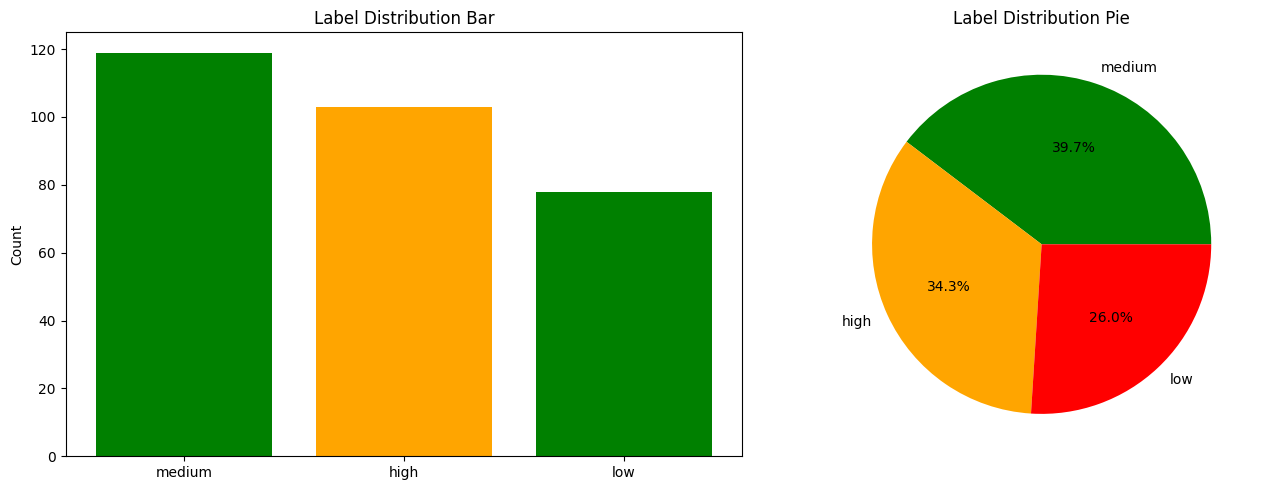

In [23]:
# Pie chart + bar side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts = df['match_label'].str.lower().value_counts()
axes[0].bar(counts.index, counts.values, color=['green', 'orange'])
axes[0].set_title('Label Distribution Bar')
axes[0].set_ylabel('Count')

axes[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%', colors=['green', 'orange', 'red'])
axes[1].set_title('Label Distribution Pie')
plt.tight_layout()

plt.show()

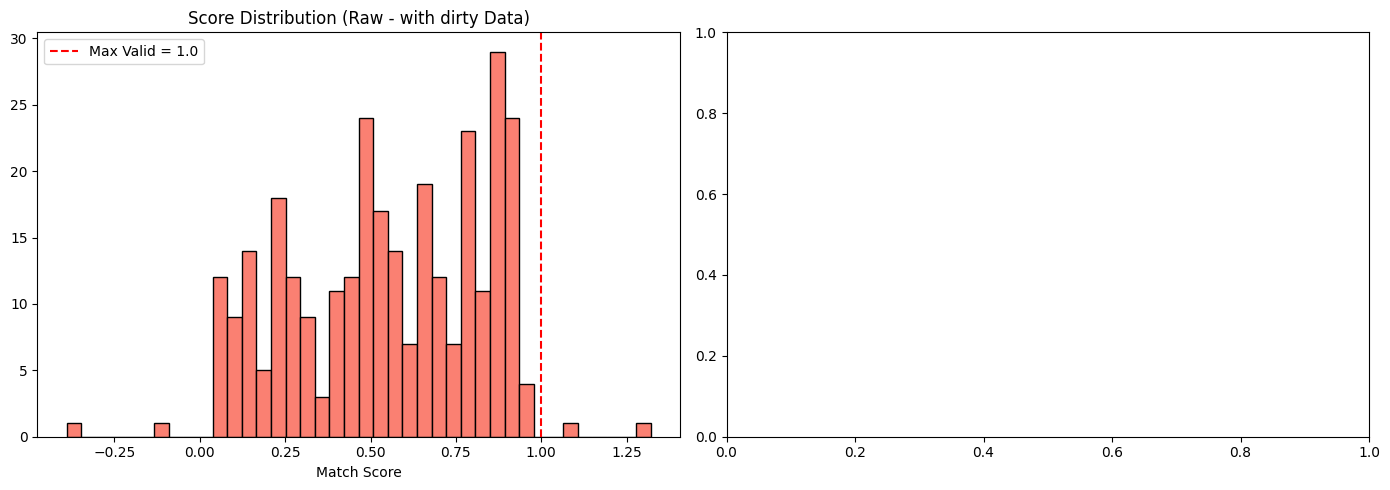

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before Cleaning
axes[0].hist(df['match_score'], bins=40, color='salmon', edgecolor='black')
axes[0].set_title('Score Distribution (Raw - with dirty Data)')
axes[0].set_xlabel('Match Score')
axes[0].axvline(1.0, color='red', linestyle='--', label='Max Valid = 1.0')
axes[0].legend()

plt.tight_layout()
plt.show()

/tmp/ipykernel_1147/334325512.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_plot, x='match_label', y='match_score', order=['low', 'medium', 'high'], palette=['red', 'orange', 'green'] )


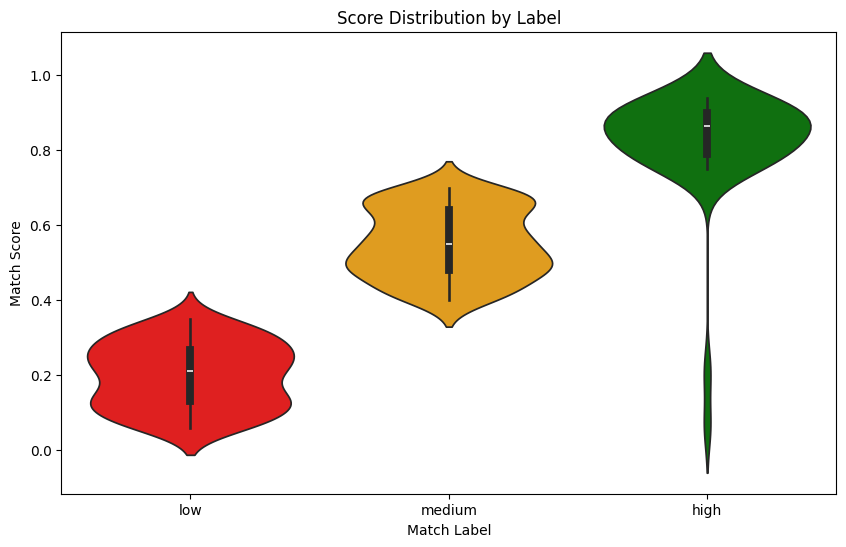

In [26]:
from ast import match_case
df_plot = df.copy()
df_plot['match_label'] = df_plot['match_label'].str.lower()
df_plot = df_plot[(df_plot['match_score'] >= 0) & (df_plot['match_score'] <= 1)]

plt.figure(figsize=(10, 6))
sns.violinplot(data=df_plot, x='match_label', y='match_score', order=['low', 'medium', 'high'], palette=['red', 'orange', 'green'] )
plt.title('Score Distribution by Label')
plt.xlabel('Match Label')
plt.ylabel('Match Score')
plt.show()

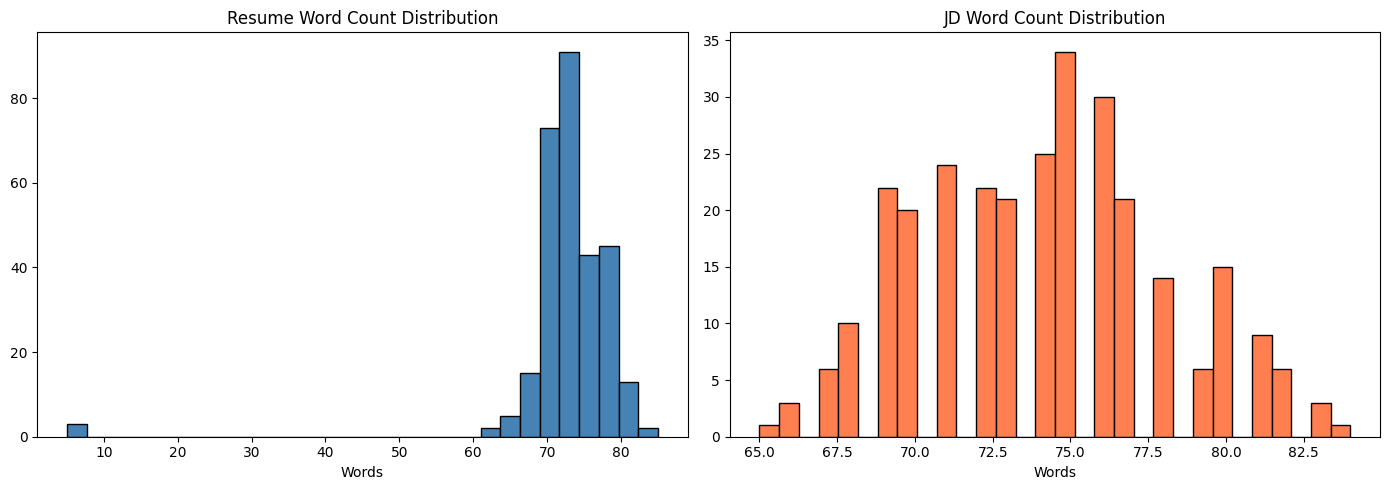

In [28]:
df_plot['resume_len'] = df_plot['resume_text'].str.split().str.len()
df_plot['jd_len'] = df_plot['job_description'].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_plot['resume_len'], bins=30, color='steelblue', edgecolor='black')
axes[0].set_title('Resume Word Count Distribution')
axes[0].set_xlabel('Words')

axes[1].hist(df_plot['jd_len'], bins=30, color='coral', edgecolor='black')
axes[1].set_title('JD Word Count Distribution')
axes[1].set_xlabel('Words')

plt.tight_layout()
plt.show()

Resume Word Count Correlation: -0.06982648484427288
JD Word Count Correlation: -0.1724151983078298


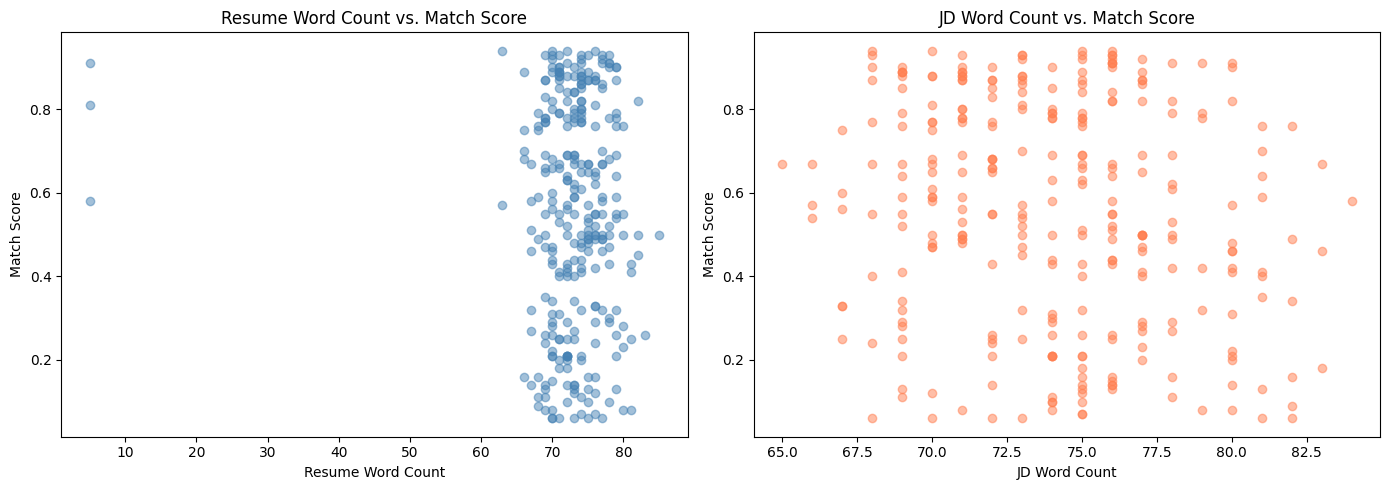

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df_plot['resume_len'], df_plot['match_score'], color='steelblue', alpha=0.5)
axes[0].set_title('Resume Word Count vs. Match Score')
axes[0].set_xlabel('Resume Word Count')
axes[0].set_ylabel('Match Score')

axes[1].scatter(df_plot['jd_len'], df_plot['match_score'], color='coral', alpha=0.5)
axes[1].set_title('JD Word Count vs. Match Score')
axes[1].set_xlabel('JD Word Count')
axes[1].set_ylabel('Match Score')

plt.tight_layout()
plt.show

# Actual correlation values
print(f"Resume Word Count Correlation: {df_plot['resume_len'].corr(df_plot['match_score'])}")
print(f"JD Word Count Correlation: {df_plot['jd_len'].corr(df_plot['match_score'])}")

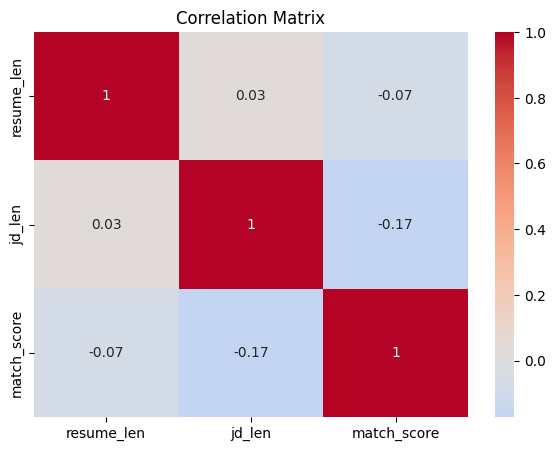

In [30]:
plt.figure(figsize=(7, 5))
corr = df_plot[['resume_len', 'jd_len', 'match_score']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

In [31]:
pip install wordcloud

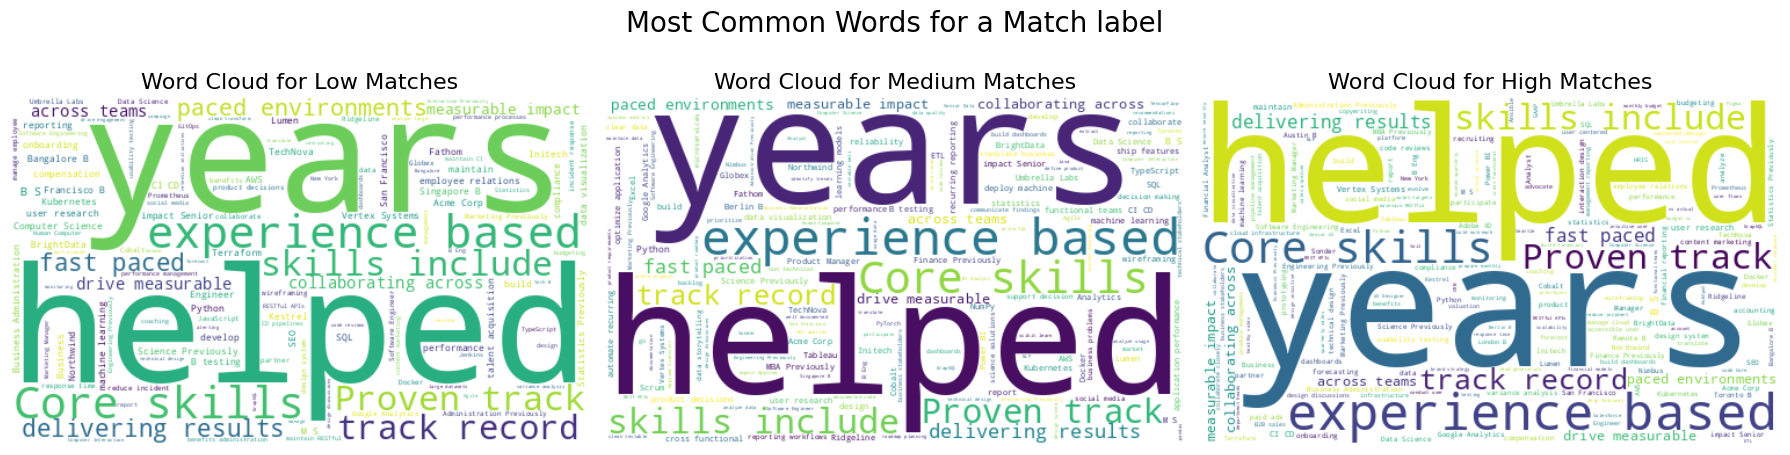

In [34]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
labels = ['low', 'medium', 'high']
colors = ['red', 'orange', 'green']

for ax, label, cmap in zip(axes, labels, colors):
    text = ' '.join(df_plot[df_plot['match_label'] == label]['resume_text'].dropna().astype(str))
    wordcloud = WordCloud(width=500, height=300, background_color='white').generate(text)
    ax.imshow(wordcloud, interpolation='bilinear')
    ax.set_title(f'Word Cloud for {label.capitalize()} Matches', fontsize=16)
    ax.axis('off')

plt.suptitle('Most Common Words for a Match label' , fontsize=20)

plt.tight_layout()
plt.show()

In [35]:
df_clean = df.copy()

In [37]:
# Problem: 'high', 'High', 'HIGH' are treated as 3 different categories
print("Before:", df_clean['match_label'].value_counts().to_dict())

df_clean['match_label'] = df_clean['match_label'].str.lower().str.strip()

print("After:", df_clean['match_label'].value_counts().to_dict())
print(f"\nUnique labels now: {df_clean['match_label'].nunique} (expected 3)")

Before: {'medium': 102, 'high': 87, 'low': 66, 'MEDIUM': 10, 'High': 9, 'HIGH': 7, 'Medium': 7, 'Low': 6, 'LOW': 6}
After: {'medium': 119, 'high': 103, 'low': 78}

Unique labels now: <bound method IndexOpsMixin.nunique of 0      medium
1         low
2         low
3      medium
4        high
        ...  
295       low
296       low
297      high
298    medium
299    medium
Name: match_label, Length: 300, dtype: object> (expected 3)


In [38]:
print(f"Before dropping nulls: {len(df_clean)} rows")

df_clean = df_clean.dropna(subset=['resume_text', 'job_description'])

print(f"After dropping nulls: {len(df_clean)} rows")
print(f"Removed: {len(df) - len(df_clean)} rows")

Before dropping nulls: 300 rows
After dropping nulls: 293 rows
Removed: 7 rows


In [39]:
print(f"Before dropping duplicates: {len(df_clean)} rows")
print(f"Duplicates pairs found: {df_clean.duplicated (subset=['resume_text', 'job_description']).sum()}")

df_clean = df_clean.drop_duplicates(subset=['resume_text', 'job_description'], keep='first')

print(f"After dropping duplicates: {len(df_clean)} rows")

Before dropping duplicates: 293 rows
Duplicates pairs found: 6
After dropping duplicates: 287 rows


In [44]:
# Scores must be in [0.0 1.0], anything else is a data error
invalid_mask = (df_clean['match_score'] < 0) | (df_clean['match_score'] > 1)
print(f"Invalid Scores found: {invalid_mask.sum()}")
print(df_clean[invalid_mask][['match_label', 'match_score']])

df_clean = df_clean[~invalid_mask]
print(f"\nRows After removing invalid scores: {len(df_clean)}")

Invalid Scores found: 0
Empty DataFrame
Columns: [match_label, match_score]
Index: []

Rows After removing invalid scores: 283


In [45]:
# Expected: low=0.05-0.35, medium=0.40-0.70, high-0.75-0.95

print("Score Range Per Label:")
print(df_clean.groupby('match_label')['match_score'].agg(['min', 'max', 'mean']))

# Flag any rows where label and score contradict each other
def label_score_mismatch(row):
  score = row['match_score']
  label = row['match_label']

  if label == 'high' and score < 0.70: return True
  if label == 'medium' and (score < 0.35 or score > 0.75): return True
  if label == 'low' and score > 0.40: return True

  return False

mismatches = df_clean.apply(label_score_mismatch, axis=1)
print(f"\nLabel-scoreMismatches found: {mismatches.sum()}")
df_clean[mismatches][['match_label', 'match_score']]

Score Range Per Label:
              min   max      mean
match_label                      
high         0.06  0.94  0.828000
low          0.06  0.35  0.198182
medium       0.40  0.70  0.550631

Label-scoreMismatches found: 3


,match_label,match_score
54,high,0.06
202,high,0.21
239,high,0.07


In [46]:
# A 15-character resume or JD is Useless for training
df_clean['resume_len'] = df_clean['resume_text'].str.split().str.len()
df_clean['jd_len'] = df_clean['job_description'].str.split().str.len()

print("Short Texts Found:")
print(f"   resume_text < 20 words: {(df_clean['resume_len'] < 20).sum()}")
print(f"   job_description < 10 words: {(df_clean['jd_len'] < 10).sum()}")

df_clean = df_clean[(df_clean['resume_len'] >= 20) & (df_clean['jd_len'] >= 10)]
print(f"\nRows After removing short texts: {len(df_clean)}")

Short Texts Found:
   resume_text < 20 words: 3
   job_description < 10 words: 0

Rows After removing short texts: 280


In [47]:
df_clean = df_clean.reset_index(drop=True)

print("=" * 45)
print("CLEANING SUMMARY")
print("="* 45)
print(f"Original Rows: {len(df)}")
print(f"Final Rows: {len(df_clean)}")
print(f"Rows Removed: {len(df) - len(df_clean)}")
print()
print(f"Nulls Remaining: {df_clean.isnull().sum().sum()}")
print(f"Duplicate Pairs Remaining: {df_clean.duplicated(subset=['resume_text', 'job_description']).sum()}")
print(f"Label Variants: {df_clean['match_label'].nunique()}")
print(f"Score Range: {df_clean['match_score'].min()} - {df_clean['match_score'].max()}")
print("Label Distribution After Cleaning:")
print(df_clean['match_label'].value_counts())
print("=" * 45)

CLEANING SUMMARY
Original Rows: 300
Final Rows: 280
Rows Removed: 20

Nulls Remaining: 0
Duplicate Pairs Remaining: 0
Label Variants: 3
Score Range: 0.06 - 0.94
Label Distribution After Cleaning:
match_label
medium    110
high       93
low        77
Name: count, dtype: int64


In [48]:
df_clean.to_csv('/content/cleaned_resumeJD_pairs.csv', index=False)
print(f"Saved: /content/cleaned_resumeJD_pairs.csv ({len(df_clean)} rows)")

Saved: /content/cleaned_resumeJD_pairs.csv (280 rows)


# Completed EDA & Data Pre-Processing Thankyou🥰!!!!